# Small Neural Networks for Fraud Detection — November Task

**Break Through Tech AI Studio × Mastercard | Banking 1B**
**Author: Kyaw Thi (Eric) Ha** ([@KTH-Sys](https://github.com/KTH-Sys)) · November 2026
**Builds on:** `BTT_Mastercard_Feature_Engineering_Final.ipynb` (team feature tables) and `BTT_Mastercard_Baseline_Modeling_Complete_Student_Notebook_MERGED_v3.ipynb` (logistic regression, LightGBM, XGBoost)

> **[Eric]** Hi team — this notebook is my November task: **train small neural networks, compare them with our other models, and evaluate how well they really work.** I wrote every step so you can follow along even if you have never trained a neural network. Each section says *what I'm trying to do*, *why*, and *what I found*. Cells marked `# [Eric]` are my code.

### The short version (read this first)

| | What I did | Where |
|---|---|---|
| 1 | Loaded the team's numeric neural-net table (`X_nn_*`), the same one logistic regression used | §2 |
| 2 | Re-ran logistic regression as the simple reference | §5 |
| 3 | Trained small multilayer perceptrons (MLPs) of three sizes | §7 |
| 4 | Tested whether weighting fraud cases in the loss helps | §8 |
| 5 | Added *embeddings* so the network can learn from high-cardinality columns like `card1` and `addr1` | §9 |
| 6 | Checked over-fitting (learning curves) and repeated the best model with 3 seeds | §10–11 |
| 7 | Compared against LightGBM, tried a blend, and evaluated with the team's metrics | §12–17 |

**Data policy (same as the team):** everything here uses **train → validation** only. The labeled **holdout is never loaded**, so it stays an honest final test for whichever model we choose.

## 0. What question am I answering?

The team's baseline notebook found that boosted trees (LightGBM, XGBoost) rank fraud much better than logistic regression (average precision about 0.61–0.63 vs 0.43). Logistic regression is a straight-line model: it adds up weighted features and cannot learn "if A **and** B then risky" by itself. A **neural network** can learn such combinations, so it is the natural next model to try.

**My questions (hypotheses in brackets):**

| # | Question | What I expect before running |
|---|---|---|
| Q1 | Does a small neural net beat logistic regression on the *same* inputs? | Yes — hidden layers can learn non-linear combinations. |
| Q2 | Does a bigger network help? | A little, then it stops helping (and may over-fit). |
| Q3 | Does giving fraud cases extra weight in the loss help? | Ranking changes little; probabilities become inflated. |
| Q4 | Do embeddings for high-cardinality categories (`card1`, `addr1`, …) help? | Yes — trees use these columns heavily, and the numeric table only has them as frequencies/encodings. |
| Q5 | How close does the best net get to LightGBM? Is it stable across seeds? | Below LightGBM (trees are usually stronger on tabular data), stable within ~0.01 AP. |
| Q6 | Does blending the net with LightGBM add anything? | Possibly a small gain, because the two models make different mistakes. |
| Q7 | Where is the net strong or weak, and are its scores trustworthy probabilities? | Weaker on segments with little history; roughly calibrated when the loss is unweighted. |

**Main metric:** average precision (AP, printed as `pr_auc`), because fraud is only ~3% of transactions. A random model scores about 0.03. I also report the business-facing numbers the team agreed on: recall at 1% false-positive rate, TFPR (legitimate alerts per fraud caught), and fraud caught when reviewing the top 5% of scores.

## 1. Setup and configuration

**What I'm doing:** importing libraries and putting every setting in one place. If you want to re-run something with a different setting, change it here instead of hunting through the notebook.

**Two settings you should know about:**
- `RETRAIN = False` — every trained model saves its validation predictions to disk. When you re-run the notebook, it **loads** those saved results instead of training again (training everything takes about 30–40 minutes on a laptop CPU). Set it to `True` to train from scratch.
- `SEEDS_FOR_STABILITY = [0, 1, 2]` — the best network is trained three times with different random starting points to see how much the score moves by chance.

In [1]:
# [Eric] Section 1 — imports and configuration
from pathlib import Path
import copy, json, time, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import (average_precision_score, roc_auc_score, roc_curve,
                             precision_recall_curve, brier_score_loss)
import torch
import torch.nn as nn

# Find the team's feature-engineering outputs whether you run from the repo root or from notebooks/
FE_CANDIDATES = [Path("outputs/feature_engineering/fe_final_v1"),
                 Path("../outputs/feature_engineering/fe_final_v1"),
                 Path("notebooks/outputs/feature_engineering/fe_final_v1")]
FE_DIR = next((p for p in FE_CANDIDATES if (p / "manifest.json").exists()), None)
assert FE_DIR is not None, "Run BTT_Mastercard_Feature_Engineering_Final.ipynb first (it writes fe_final_v1)."
OUT_DIR = FE_DIR / "neural_nets" / "eric_v1"
OUT_DIR.mkdir(parents=True, exist_ok=True)

RETRAIN = False                  # False: reuse saved predictions when they exist
SEEDS_FOR_STABILITY = [0, 1, 2]
N_THREADS = 4                    # fixed CPU threads -> repeatable timings and results
torch.set_num_threads(N_THREADS)

# Team plot colours (no default matplotlib blue): emerald, amber, charcoal, sage, rust, olive, grey
from cycler import cycler
plt.rcParams["axes.prop_cycle"] = cycler(color=["#16855A", "#A97A06", "#17211C", "#7FA88E", "#A4442B", "#6B6B2A", "#8C938E"])

# Shared neural-net training settings (explained in Section 4)
TRAIN_SETTINGS = dict(lr=1e-3, weight_decay=1e-5, batch=2048, max_epochs=25, patience=4)
MIN_LEVEL_COUNT = 20             # embedding: categories seen < 20 times in train share one "rare" slot

# Metric settings — identical to the team baseline notebook so numbers are comparable
FPR_TARGETS = [0.001, 0.005, 0.01]
DETECTION_TARGETS = [0.50, 0.60, 0.70, 0.80, 0.90]
REVIEW_RATES = [0.01, 0.05, 0.10, 0.20]
FORBIDDEN = {"isFraud", "TransactionID", "TransactionDT"}

print("Feature tables:", FE_DIR.resolve())
print("My outputs    :", OUT_DIR.resolve())
print("torch", torch.__version__, "| CPU threads", torch.get_num_threads())

Feature tables: /Users/kyawthiha/Desktop/Banking-1B-online-payment-fraud-detection-using-high-dimensional-transaction-data/outputs/feature_engineering/fe_final_v1
My outputs    : /Users/kyawthiha/Desktop/Banking-1B-online-payment-fraud-detection-using-high-dimensional-transaction-data/outputs/feature_engineering/fe_final_v1/neural_nets/eric_v1
torch 2.14.0 | CPU threads 4


## 2. Load the team's feature tables

**What I'm doing:** loading the tables the feature-engineering notebook already prepared. I do **not** redo preprocessing here, because those rules were fitted on the training period only — redoing them risks leaking validation information.

I load two versions of the same transactions:

| Table | What it contains | Who uses it here |
|---|---|---|
| `X_nn_*` | All-numeric: skewed columns log-transformed, outliers clipped, missing values filled with the training median, then standardized (mean 0, std 1). Missing-value flags and one-hot columns for low-cardinality categories. | Logistic regression and all neural nets |
| `X_tree_*` | Original categories kept as categories, missing values kept as missing | LightGBM, and the **category columns** I turn into embeddings |

**Checks I run (and why):** labels line up with rows (otherwise a transaction gets someone else's label — a silent disaster), no forbidden columns (`isFraud`, `TransactionID`, `TransactionDT`), no missing or infinite values in the numeric table (a single `NaN` makes a neural network output `NaN` for everything).

In [2]:
# [Eric] Section 2 — load and check the feature tables (holdout is NOT loaded)
manifest = json.loads((FE_DIR / "manifest.json").read_text())

def load_features(split, kind):
    X = pd.read_parquet(FE_DIR / f"X_{kind}_{split}.parquet")
    y = pd.read_parquet(FE_DIR / f"y_{split}.parquet")["isFraud"]
    assert X.index.equals(y.index), f"rows and labels misaligned for {kind}/{split}"
    assert FORBIDDEN.isdisjoint(X.columns), f"forbidden predictor in {kind}/{split}"
    assert not X.columns.duplicated().any()
    return X, y

Xn_train, y_train = load_features("train", "nn")
Xn_val, y_val = load_features("validation", "nn")
assert Xn_train.columns.equals(Xn_val.columns)
assert np.isfinite(Xn_train.to_numpy()).all() and np.isfinite(Xn_val.to_numpy()).all()

X_tree_train, _ = load_features("train", "tree")
X_tree_val, _ = load_features("validation", "tree")
assert X_tree_train.index.equals(Xn_train.index) and X_tree_val.index.equals(Xn_val.index)
amount_val = X_tree_val["TransactionAmt"].to_numpy(dtype=float)   # raw dollars, for dollar-capture metrics

print(f"Train      : {len(Xn_train):,} rows | fraud rate {y_train.mean():.2%}")
print(f"Validation : {len(Xn_val):,} rows | fraud rate {y_val.mean():.2%}")
print(f"Numeric (nn) table: {Xn_train.shape[1]} columns | tree table: {X_tree_train.shape[1]} columns")
print("Holdout was NOT loaded.")

Train      : 472,432 rows | fraud rate 3.51%
Validation : 59,054 rows | fraud rate 3.13%
Numeric (nn) table: 515 columns | tree table: 537 columns
Holdout was NOT loaded.


### 2a. Which category columns get embeddings?

The numeric table one-hot encodes only categories with **≤ 10 levels** (e.g. `ProductCD`, `card4`, `card6`). High-cardinality columns such as `card1` (thousands of card-number groups) or `addr1` enter only indirectly — through frequency counts and target encodings. A neural network can instead learn an **embedding**: a short list of numbers (a vector) for every category value, learned during training, so that values with similar fraud behaviour end up close together.

There is a second group: `card1`, `card2`, `card3`, `card5`, `addr1`, `addr2` are **ID codes stored as numbers**. In the numeric table they are standardized like amounts, which tells the network that card group 9500 is "bigger" than 7919 — meaningless. As categories, each ID can get its own vector.

**What I'm doing below:** taking every categorical column that was *not* one-hot encoded, plus those six ID-like columns, and turning each value into an integer index. A missing value is treated as its own category (`__MISSING__`), because the EDA showed missingness itself carries fraud signal. Index `0` is a shared slot for values that are **rare** (seen fewer than 20 times in training) or **unseen** (appear only in validation). Rare values get no individual vector because 5 examples are not enough to learn one reliably. The mapping is learned from training data only.

In [3]:
# [Eric] Section 2a — integer indices for the embedding columns (mapping learned on TRAIN only)
cat_cols = manifest["categorical_columns"]
onehot_cols = set(manifest["nn_track"]["onehot_columns"])
# card1/card2/card3/card5/addr1/addr2 are ID codes stored as numbers: "card1 = 9500" is not "bigger" than 7919,
# so as plain numbers their order is meaningless. Treating them as categories lets the net learn one vector per ID.
ID_LIKE_NUMERIC = ["card1", "card2", "card3", "card5", "addr1", "addr2"]
emb_cols = [c for c in cat_cols if c not in onehot_cols] + ID_LIKE_NUMERIC
emb_cols = [c for c in emb_cols if c in X_tree_train.columns]

def as_labels(s):
    # Text labels; a missing value becomes its own label "__MISSING__" (missingness carries fraud signal, see EDA)
    return pd.Series(np.where(s.isna(), "__MISSING__", s.astype("object").astype(str)), index=s.index)

def category_index(train_col, other_col, min_count=MIN_LEVEL_COUNT):
    counts = as_labels(train_col).value_counts()
    kept = counts.index[counts >= min_count]
    to_idx = lambda s: pd.Categorical(as_labels(s), categories=kept).codes.astype(np.int64) + 1
    return to_idx(train_col), to_idx(other_col), len(kept) + 1     # +1 for the rare/unseen slot 0

emb_info, cat_tr_list, cat_va_list = [], [], []
for c in emb_cols:
    tr_idx, va_idx, n_levels = category_index(X_tree_train[c], X_tree_val[c])
    cat_tr_list.append(tr_idx); cat_va_list.append(va_idx)
    emb_info.append({"column": c, "levels_in_train": X_tree_train[c].nunique(dropna=False),
                     "embedding_rows": n_levels, "val_share_rare_or_unseen": float((va_idx == 0).mean())})
Xc_train = np.stack(cat_tr_list, axis=1)
Xc_val = np.stack(cat_va_list, axis=1)
CAT_LEVELS = [e["embedding_rows"] for e in emb_info]
display(pd.DataFrame(emb_info).set_index("column"))

/var/folders/88/g9t90x2942j1s1z1sbdpz2640000gn/T/ipykernel_56309/4247474037.py:17: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  to_idx = lambda s: pd.Categorical(as_labels(s), categories=kept).codes.astype(np.int64) + 1
/var/folders/88/g9t90x2942j1s1z1sbdpz2640000gn/T/ipykernel_56309/4247474037.py:17: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  to_idx = lambda s: pd.Categorical(as_labels(s), categories=kept).codes.astype(np.int64) + 1
/var/folders/88/g9t90x2942j1s1z1sbdpz2640000gn/T/ipykernel_56309/4247474037.py:17: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  to_idx = lambda s: pd.Categorical

/var/folders/88/g9t90x2942j1s1z1sbdpz2640000gn/T/ipykernel_56309/4247474037.py:17: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  to_idx = lambda s: pd.Categorical(as_labels(s), categories=kept).codes.astype(np.int64) + 1
/var/folders/88/g9t90x2942j1s1z1sbdpz2640000gn/T/ipykernel_56309/4247474037.py:17: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  to_idx = lambda s: pd.Categorical(as_labels(s), categories=kept).codes.astype(np.int64) + 1
/var/folders/88/g9t90x2942j1s1z1sbdpz2640000gn/T/ipykernel_56309/4247474037.py:17: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  to_idx = lambda s: pd.Categorical

/var/folders/88/g9t90x2942j1s1z1sbdpz2640000gn/T/ipykernel_56309/4247474037.py:17: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  to_idx = lambda s: pd.Categorical(as_labels(s), categories=kept).codes.astype(np.int64) + 1
/var/folders/88/g9t90x2942j1s1z1sbdpz2640000gn/T/ipykernel_56309/4247474037.py:17: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  to_idx = lambda s: pd.Categorical(as_labels(s), categories=kept).codes.astype(np.int64) + 1


/var/folders/88/g9t90x2942j1s1z1sbdpz2640000gn/T/ipykernel_56309/4247474037.py:17: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  to_idx = lambda s: pd.Categorical(as_labels(s), categories=kept).codes.astype(np.int64) + 1
/var/folders/88/g9t90x2942j1s1z1sbdpz2640000gn/T/ipykernel_56309/4247474037.py:17: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  to_idx = lambda s: pd.Categorical(as_labels(s), categories=kept).codes.astype(np.int64) + 1


/var/folders/88/g9t90x2942j1s1z1sbdpz2640000gn/T/ipykernel_56309/4247474037.py:17: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  to_idx = lambda s: pd.Categorical(as_labels(s), categories=kept).codes.astype(np.int64) + 1
/var/folders/88/g9t90x2942j1s1z1sbdpz2640000gn/T/ipykernel_56309/4247474037.py:17: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  to_idx = lambda s: pd.Categorical(as_labels(s), categories=kept).codes.astype(np.int64) + 1


/var/folders/88/g9t90x2942j1s1z1sbdpz2640000gn/T/ipykernel_56309/4247474037.py:17: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  to_idx = lambda s: pd.Categorical(as_labels(s), categories=kept).codes.astype(np.int64) + 1
/var/folders/88/g9t90x2942j1s1z1sbdpz2640000gn/T/ipykernel_56309/4247474037.py:17: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  to_idx = lambda s: pd.Categorical(as_labels(s), categories=kept).codes.astype(np.int64) + 1


/var/folders/88/g9t90x2942j1s1z1sbdpz2640000gn/T/ipykernel_56309/4247474037.py:17: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  to_idx = lambda s: pd.Categorical(as_labels(s), categories=kept).codes.astype(np.int64) + 1
/var/folders/88/g9t90x2942j1s1z1sbdpz2640000gn/T/ipykernel_56309/4247474037.py:17: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  to_idx = lambda s: pd.Categorical(as_labels(s), categories=kept).codes.astype(np.int64) + 1


/var/folders/88/g9t90x2942j1s1z1sbdpz2640000gn/T/ipykernel_56309/4247474037.py:17: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  to_idx = lambda s: pd.Categorical(as_labels(s), categories=kept).codes.astype(np.int64) + 1
/var/folders/88/g9t90x2942j1s1z1sbdpz2640000gn/T/ipykernel_56309/4247474037.py:17: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  to_idx = lambda s: pd.Categorical(as_labels(s), categories=kept).codes.astype(np.int64) + 1


,levels_in_train,embedding_rows,val_share_rare_or_unseen
column,,,
P_emaildomain,60,61,0.000000
R_emaildomain,61,57,0.000000
id_30,73,70,0.000576
id_31,111,84,0.020219
id_33,213,60,0.002523
P_provider,45,46,0.000000
device_family,17,18,0.000000
card1,12730,2253,0.100688
card2,501,500,0.000034


## 3. Evaluation metrics (copied from the team notebook)

**What I'm doing:** reusing the team's `evaluate()` function **unchanged**, so my numbers can be put in the same table as LightGBM, XGBoost and logistic regression.

Quick reminder of the confusion-matrix words (we flag a transaction as "positive" = suspected fraud):

- **Recall / detection rate** = caught fraud ÷ all fraud.
- **Precision** = caught fraud ÷ everything we flagged.
- **FPR** = legitimate payments flagged ÷ all legitimate payments.
- **TFPR** (advisor's ratio) = legitimate payments flagged ÷ fraud caught. "0.5:1" means one false alert for every two frauds caught.
- **AP (`pr_auc`)**: one number summarizing precision across all recall levels. No-skill ≈ fraud rate (≈ 0.03).
- **ROC-AUC**: chance that a random fraud is scored above a random legitimate payment.
- **KS**: the largest gap between the share of fraud and the share of legitimate payments flagged.
- **Top-k% capture**: if analysts review only the riskiest k% of payments, what share of fraud cases (and fraud dollars) do they find?

In [4]:
# [Eric] Section 3 — team metric helpers, copied unchanged from the baseline notebook (Section 3)
def ranked_operating_points(y, score):
    y = np.asarray(y, dtype=int); s = np.asarray(score, dtype=float)
    if len(y) != len(s) or not np.isfinite(s).all():
        raise ValueError("Scores must be finite and aligned to labels")
    order = np.argsort(-s, kind="stable")
    y_sort, s_sort = y[order], s[order]
    n_fraud = int(y.sum()); n_legit = len(y) - n_fraud
    group_end = np.r_[np.flatnonzero(np.diff(s_sort) != 0), len(s_sort) - 1]
    tp = np.cumsum(y_sort)[group_end]; flagged = group_end + 1; fp = flagged - tp
    return pd.DataFrame({"threshold": s_sort[group_end], "tp": tp, "fp": fp,
                         "recall": tp / n_fraud, "fpr": fp / n_legit,
                         "tfpr": np.divide(fp, tp, out=np.full(len(tp), np.nan), where=tp > 0),
                         "review_rate": flagged / len(y)})


def evaluate(y, score, amount):
    y = np.asarray(y, dtype=int); s = np.asarray(score, dtype=float); amt = np.asarray(amount, dtype=float)
    op = ranked_operating_points(y, s)
    roc_fpr, roc_tpr, _ = roc_curve(y, s)
    out = {"fraud_rate": y.mean(), "pr_auc": average_precision_score(y, s),
           "roc_auc": roc_auc_score(y, s), "ks": float(np.max(roc_tpr - roc_fpr))}
    for budget in FPR_TARGETS:
        allowed = op.loc[op.fpr <= budget, "recall"]
        out[f"recall_at_{budget * 100:g}pct_fpr"] = float(allowed.max()) if len(allowed) else 0.0
    for target in DETECTION_TARGETS:
        eligible = op.loc[op.recall >= target]
        first = eligible.iloc[0] if len(eligible) else None
        suffix = f"{int(target * 100)}pct_detection"
        out[f"tfpr_at_{suffix}"] = float(first.tfpr) if first is not None else np.nan
        out[f"review_rate_at_{suffix}"] = float(first.review_rate) if first is not None else np.nan
    order = np.argsort(-s, kind="stable"); ys, amts = y[order], amt[order]
    n_fraud = int(y.sum()); total_fraud_amt = float(np.sum(amt * y))
    for k in REVIEW_RATES:
        top_n = max(1, int(round(len(y) * k)))
        out[f"fraud_cases_top{k * 100:g}pct"] = float(ys[:top_n].sum() / n_fraud)
        out[f"fraud_dollars_top{k * 100:g}pct"] = float((ys[:top_n] * amts[:top_n]).sum()) / total_fraud_amt
    return out


HEADLINE = ["pr_auc", "roc_auc", "ks", "recall_at_1pct_fpr", "tfpr_at_50pct_detection",
            "tfpr_at_80pct_detection", "fraud_cases_top5pct", "fraud_dollars_top5pct"]

example = evaluate([1, 0, 1, 0], [0.9, 0.8, 0.4, 0.1], [100, 20, 40, 50])
assert np.isclose(example["fraud_rate"], 0.5) and np.isclose(example["tfpr_at_50pct_detection"], 0.0)
print("Metric helpers passed the team's 4-transaction smoke test.")

Metric helpers passed the team's 4-transaction smoke test.


## 4. How a small neural network works (plain-English version)

**Start from logistic regression.** It computes one weighted sum of the inputs and squashes it into a probability:

$$p(\text{fraud}) = \sigma(b + w_1x_1 + \dots + w_px_p), \qquad \sigma(z) = \frac{1}{1+e^{-z}}$$

**A neural network adds "hidden layers" in between.** Each hidden *neuron* computes its own weighted sum, then applies **ReLU** (keep the value if positive, otherwise output 0). The next layer combines those outputs again. Because ReLU bends the straight line, stacking layers lets the network build rules like "small amount **and** new device **and** unusual email domain → risky" without us writing them by hand.

```
 515 inputs ──► [256 neurons, ReLU] ──► [128 neurons, ReLU] ──► 1 output ──► sigmoid ──► fraud score
   (+ embeddings)     hidden layer 1          hidden layer 2
```

A network with **zero** hidden layers *is* logistic regression. So the comparison in this notebook directly answers: "does adding hidden layers help?"

**How it learns:**

| Term | Meaning |
|---|---|
| **Loss (binary cross-entropy)** | A penalty that is large when the model gives a fraud a low score or a legitimate payment a high score. Training = making this number small. |
| **Mini-batch** | Instead of looking at all 472k rows at once, the model looks at 2,048 rows, adjusts its weights a little, then takes the next 2,048. |
| **Epoch** | One full pass over all training rows (≈ 231 mini-batches). |
| **Adam (learning rate 0.001)** | The rule for how big each weight adjustment is. A standard, robust default. |
| **Batch normalization** | Re-centres each layer's outputs during training; makes training faster and more stable. |
| **Dropout (0.1–0.3)** | Randomly switches off some neurons during training so the network cannot rely on any single path — a guard against memorizing the training data. |
| **Weight decay (1e-5)** | A tiny penalty on large weights (like the `C` in logistic regression). |
| **Early stopping (patience 4)** | After every epoch I score the validation set. I keep the epoch with the best validation AP and stop when 4 epochs in a row fail to improve. |

**Caveat about early stopping:** like the tree models' early stopping in the baseline notebook, it peeks at validation labels to choose *when to stop*. That makes all validation scores slightly optimistic. It affects every model equally, and the untouched holdout will give the honest number later.

In [5]:
# [Eric] Section 4 — the network, prediction, and training loop
def emb_dim(n_levels):
    # Rule of thumb from fast.ai: more levels -> longer vector, capped at 16
    return int(min(16, round(1.6 * n_levels ** 0.56)))


class TabularMLP(nn.Module):
    # Numeric inputs (+ optional category embeddings) -> hidden layers -> one fraud logit
    def __init__(self, n_num, hidden=(256, 128), dropout=0.2, cat_levels=()):
        super().__init__()
        self.embs = nn.ModuleList([nn.Embedding(n, emb_dim(n)) for n in cat_levels])
        d = n_num + sum(emb_dim(n) for n in cat_levels)
        layers = []
        for h in hidden:
            layers += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            d = h
        layers.append(nn.Linear(d, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x_num, x_cat=None):
        if len(self.embs):
            x_num = torch.cat([x_num] + [e(x_cat[:, i]) for i, e in enumerate(self.embs)], dim=1)
        return self.net(x_num).squeeze(1)


@torch.no_grad()
def predict(model, Xn, Xc=None, batch=16384):
    model.eval()
    parts = []
    for i in range(0, len(Xn), batch):
        parts.append(torch.sigmoid(model(Xn[i:i + batch], None if Xc is None else Xc[i:i + batch])))
    return torch.cat(parts).numpy()


def train_mlp(hidden, dropout, pos_weight=1.0, use_embeddings=False, seed=0, verbose=True,
              lr=1e-3, weight_decay=1e-5, batch=2048, max_epochs=25, patience=4):
    torch.manual_seed(seed); np.random.seed(seed)
    levels = CAT_LEVELS if use_embeddings else ()
    xc_tr, xc_va = (Tc_train, Tc_val) if use_embeddings else (None, None)
    model = TabularMLP(Tn_train.shape[1], hidden, dropout, levels)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(float(pos_weight)))
    gen = torch.Generator().manual_seed(seed)
    best = {"ap": -1.0}; bad = 0; history = []
    for epoch in range(1, max_epochs + 1):
        t0 = time.perf_counter(); model.train(); total = 0.0
        perm = torch.randperm(len(Tn_train), generator=gen)
        for i in range(0, len(perm), batch):
            idx = perm[i:i + batch]
            logits = model(Tn_train[idx], None if xc_tr is None else xc_tr[idx])
            loss = loss_fn(logits, Ty_train[idx])
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(idx)
        val_score = predict(model, Tn_val, xc_va)
        ap = average_precision_score(y_val, val_score)
        history.append({"epoch": epoch, "train_loss": total / len(perm), "val_ap": ap,
                        "seconds": time.perf_counter() - t0})
        if verbose:
            print(f"   epoch {epoch:2d} | train loss {history[-1]['train_loss']:.4f} | val AP {ap:.4f} | {history[-1]['seconds']:.0f}s")
        if ap > best["ap"]:
            best = {"ap": ap, "epoch": epoch, "state": copy.deepcopy(model.state_dict()), "score": val_score}; bad = 0
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best["state"])
    n_params = sum(p.numel() for p in model.parameters())
    return model, best["score"], pd.DataFrame(history), best["epoch"], n_params


# Convert the pandas tables to torch tensors once (float32 numbers, int64 category indices)
Tn_train = torch.from_numpy(Xn_train.to_numpy(np.float32, copy=True))
Tn_val = torch.from_numpy(Xn_val.to_numpy(np.float32, copy=True))
Ty_train = torch.from_numpy(y_train.to_numpy(np.float32, copy=True))
Tc_train = torch.as_tensor(Xc_train)
Tc_val = torch.as_tensor(Xc_val)
print("Tensors ready:", tuple(Tn_train.shape), tuple(Tc_train.shape))

Tensors ready: (472432, 515) (472432, 13)


### 4a. Bookkeeping: one function that trains (or reloads) and scores every model

**What I'm doing:** wrapping training in `run_experiment()`. It (1) loads saved predictions if they exist and `RETRAIN` is `False`, otherwise trains; (2) saves validation predictions and the epoch-by-epoch history; (3) scores the predictions with the team's `evaluate()`; (4) adds a row to one results table, `RESULTS`. Every model in this notebook goes through this function, so every model is treated identically.

In [6]:
# [Eric] Section 4a — train-or-load wrapper and the shared results table
RESULTS, SCORES, HISTORIES = [], {}, {}

def run_experiment(name, question, seed=0, **cfg):
    pred_file, hist_file = OUT_DIR / f"{name}__seed{seed}_val_predictions.parquet", OUT_DIR / f"{name}__seed{seed}_history.json"
    if pred_file.exists() and hist_file.exists() and not RETRAIN:
        score = pd.read_parquet(pred_file)["score"].to_numpy()
        info = json.loads(hist_file.read_text())
        history, best_epoch, n_params, seconds = pd.DataFrame(info["history"]), info["best_epoch"], info["n_params"], info["seconds"]
        print(f"{name} (seed {seed}): loaded saved predictions")
    else:
        print(f"{name} (seed {seed}): training {cfg}")
        t0 = time.perf_counter()
        _, score, history, best_epoch, n_params = train_mlp(seed=seed, **cfg)
        seconds = time.perf_counter() - t0
        pd.DataFrame({"row_index": Xn_val.index, "y": y_val.to_numpy(), "score": score}).to_parquet(pred_file)
        hist_file.write_text(json.dumps({"history": history.to_dict("records"), "best_epoch": best_epoch,
                                         "n_params": n_params, "seconds": seconds, "config": cfg}, default=str))
    metrics = evaluate(y_val, score, amount_val)
    RESULTS.append({"model": name, "question": question, "seed": seed, "n_params": n_params,
                    "best_epoch": best_epoch, "train_minutes": seconds / 60, **metrics})
    SCORES[(name, seed)], HISTORIES[(name, seed)] = score, history
    print(f"   -> val AP {metrics['pr_auc']:.4f} | ROC-AUC {metrics['roc_auc']:.4f} | "
          f"recall@1%FPR {metrics['recall_at_1pct_fpr']:.3f} | best epoch {best_epoch} | {n_params:,} weights")
    return score


def show(models=None, cols=HEADLINE):
    df = pd.DataFrame(RESULTS)
    if models is not None:
        df = df[df.model.isin(models)]
    return df[["model", "seed", "n_params", "best_epoch"] + cols].round(4)

## 5. Reference model: logistic regression (same settings as the team's Track B)

**What I'm doing:** re-running the team's logistic regression (`C=0.1`, `class_weight="balanced"`, `max_iter=1500`) on exactly the same table and rows. Re-running it here — rather than copying the number — confirms that my data loading matches the team's (expected AP ≈ 0.428). It is the "zero hidden layers" version of every network that follows.

In [7]:
# [Eric] Section 5 — logistic regression reference (team Track B settings)
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning

lr_file = OUT_DIR / "logistic_regression__seed0_val_predictions.parquet"
if lr_file.exists() and not RETRAIN:
    lr_score, lr_seconds = pd.read_parquet(lr_file)["score"].to_numpy(), float("nan")
    print("logistic regression: loaded saved predictions")
else:
    t0 = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        logreg = LogisticRegression(C=0.1, max_iter=1500, class_weight="balanced").fit(Xn_train, y_train)
    for w in caught:
        print("Convergence notice:", w.message)
    lr_score, lr_seconds = logreg.predict_proba(Xn_val)[:, 1], time.perf_counter() - t0
    pd.DataFrame({"row_index": Xn_val.index, "y": y_val.to_numpy(), "score": lr_score}).to_parquet(lr_file)

RESULTS.append({"model": "logistic_regression", "question": "reference", "seed": 0,
                "n_params": Xn_train.shape[1] + 1, "best_epoch": np.nan, "train_minutes": lr_seconds / 60,
                **evaluate(y_val, lr_score, amount_val)})
SCORES[("logistic_regression", 0)] = lr_score
display(show(["logistic_regression"]))

logistic regression: loaded saved predictions


,model,seed,n_params,best_epoch,pr_auc,roc_auc,ks,recall_at_1pct_fpr,tfpr_at_50pct_detection,tfpr_at_80pct_detection,fraud_cases_top5pct,fraud_dollars_top5pct
0,logistic_regression,0,516,NaN,0.4273,0.8668,0.5699,0.376,1.9935,9.0804,0.5084,0.4658


## 6. Experiment plan for the networks

To keep comparisons fair I change **one thing at a time** and keep everything else fixed (same rows, same inputs, same optimizer, same early-stopping rule, seed 0):

| Model name | Hidden layers | Dropout | Loss weight on fraud | Embeddings | Question |
|---|---|---|---|---|---|
| `net_0_hidden` | none (= logistic regression trained with the network's loop) | 0 | 1 | no | Q1 control |
| `mlp_tiny` | 64 | 0.1 | 1 | no | Q1, Q2 |
| `mlp_small` | 256 → 128 | 0.2 | 1 | no | Q1, Q2 |
| `mlp_medium` | 512 → 256 → 128 | 0.3 | 1 | no | Q2 |
| `mlp_small_weighted` | 256 → 128 | 0.2 | √(legit/fraud) ≈ 5.2 | no | Q3 |
| `mlp_small_emb` | 256 → 128 | 0.2 | 1 | yes | Q4 |

"Small" is deliberate: the assignment is a **small** neural-net baseline, and these models train in a few minutes on a laptop CPU.

## 7. Experiment 1 — does a hidden layer help, and how big should the network be? (Q1, Q2)

**What I'm doing:** first a network with **zero** hidden layers. That is logistic regression, but trained with exactly the same loop, optimizer and early stopping as the real networks — so if the hidden-layer networks beat it, the only explanation is the hidden layers. Then three sizes of network without embeddings or loss weighting. If even the tiny network beats the zero-hidden-layer model, the extra flexibility of hidden layers is what helps (the inputs are identical). If medium is no better than small, bigger is not worth it.

**Watch the printed epochs:** training loss should go down every epoch. Validation AP usually rises for a few epochs and then flattens or falls — that is the point where the network starts memorizing training-period patterns, and early stopping keeps the best epoch.

In [8]:
# [Eric] Section 7 — network size
run_experiment("net_0_hidden", "Q1 control", hidden=(), dropout=0.0)
run_experiment("mlp_tiny", "Q1/Q2 size", hidden=(64,), dropout=0.1)
run_experiment("mlp_small", "Q1/Q2 size", hidden=(256, 128), dropout=0.2)
run_experiment("mlp_medium", "Q2 size", hidden=(512, 256, 128), dropout=0.3)
display(show(["logistic_regression", "net_0_hidden", "mlp_tiny", "mlp_small", "mlp_medium"]))

net_0_hidden (seed 0): loaded saved predictions


   -> val AP 0.4377 | ROC-AUC 0.8534 | recall@1%FPR 0.380 | best epoch 17 | 516 weights
mlp_tiny (seed 0): loaded saved predictions
   -> val AP 0.4809 | ROC-AUC 0.8820 | recall@1%FPR 0.411 | best epoch 7 | 33,217 weights
mlp_small (seed 0): loaded saved predictions
   -> val AP 0.5098 | ROC-AUC 0.8921 | recall@1%FPR 0.446 | best epoch 9 | 165,889 weights
mlp_medium (seed 0): loaded saved predictions


   -> val AP 0.5294 | ROC-AUC 0.8882 | recall@1%FPR 0.479 | best epoch 18 | 430,337 weights


,model,seed,n_params,best_epoch,pr_auc,roc_auc,ks,recall_at_1pct_fpr,tfpr_at_50pct_detection,tfpr_at_80pct_detection,fraud_cases_top5pct,fraud_dollars_top5pct
0,logistic_regression,0,516,NaN,0.4273,0.8668,0.5699,0.3760,1.9935,9.0804,0.5084,0.4658
1,net_0_hidden,0,516,17.0,0.4377,0.8534,0.5546,0.3803,2.0151,10.7718,0.5073,0.4671
2,mlp_tiny,0,33217,7.0,0.4809,0.8820,0.6164,0.4111,1.5670,7.8697,0.5451,0.5072
3,mlp_small,0,165889,9.0,0.5098,0.8921,0.6327,0.4462,1.1004,6.6523,0.5775,0.5539
4,mlp_medium,0,430337,18.0,0.5294,0.8882,0.6334,0.4787,0.7927,6.9669,0.6013,0.5724


### 7a. What I see — Experiment 1
**[Eric]** Here is what this tells us (validation AP, seed 0):

| Model | Weights | AP | Recall at 1% FPR | Legit alerts per fraud at 50% detection |
|---|---:|---:|---:|---:|
| Logistic regression (team settings) | 516 | 0.427 | 37.6% | 1.99 |
| `net_0_hidden` (same thing, my training loop) | 516 | 0.438 | 38.0% | 2.02 |
| `mlp_tiny` (64) | 33k | 0.481 | 41.1% | 1.57 |
| `mlp_small` (256 → 128) | 166k | 0.510 | 44.6% | 1.10 |
| `mlp_medium` (512 → 256 → 128) | 430k | 0.529 | 47.9% | 0.79 |

- **Q1 — yes, hidden layers help.** The zero-hidden-layer network lands right next to logistic regression (0.438 vs 0.427), so my training loop is not secretly better on its own. Adding **one** hidden layer of 64 neurons jumps AP to 0.481. The inputs and rows are identical, so the gain comes from the network learning combinations of features.
- **Q2 — bigger helps, but less each time.** 33k → 166k weights adds +0.029 AP; 166k → 430k adds +0.019, while training takes about 3× longer (1.9 vs 0.6 minutes). This is a single seed, so treat the medium-vs-small gap as likely but not proven (Section 11 shows a seed spread of about ±0.005 for `mlp_small`).
- **In business terms:** at a 1% false-alarm budget, the small network catches about 45 of every 100 frauds versus 38 for logistic regression.

## 8. Experiment 2 — does weighting fraud cases in the loss help? (Q3)

**Why ask this:** only ~3.5% of training rows are fraud, so most of the loss comes from legitimate payments. Setting `pos_weight` = 5.2 makes each fraud row count about 5× in the loss. Logistic regression used `class_weight="balanced"` (≈ 27×), so it is fair to check what weighting does to a network.

**What to expect:** AP and ROC-AUC measure *ranking*, and weighting mostly shifts all scores upward without reordering them much. The side effect is that scores stop being honest probabilities (checked in Section 15).

In [9]:
# [Eric] Section 8 — loss weighting
neg, pos = int((y_train == 0).sum()), int((y_train == 1).sum())
POS_WEIGHT = float(np.sqrt(neg / pos))
print(f"legit/fraud = {neg/pos:.1f}  ->  pos_weight = sqrt(legit/fraud) = {POS_WEIGHT:.2f}")
run_experiment("mlp_small_weighted", "Q3 imbalance", hidden=(256, 128), dropout=0.2, pos_weight=POS_WEIGHT)
display(show(["mlp_small", "mlp_small_weighted"]))

legit/fraud = 27.5  ->  pos_weight = sqrt(legit/fraud) = 5.24
mlp_small_weighted (seed 0): loaded saved predictions


   -> val AP 0.5335 | ROC-AUC 0.8968 | recall@1%FPR 0.464 | best epoch 15 | 165,889 weights


,model,seed,n_params,best_epoch,pr_auc,roc_auc,ks,recall_at_1pct_fpr,tfpr_at_50pct_detection,tfpr_at_80pct_detection,fraud_cases_top5pct,fraud_dollars_top5pct
3,mlp_small,0,165889,9.0,0.5098,0.8921,0.6327,0.4462,1.1004,6.6523,0.5775,0.5539
5,mlp_small_weighted,0,165889,15.0,0.5335,0.8968,0.6502,0.4641,0.8510,5.8994,0.5889,0.5527


### 8a. What I see — Experiment 2
**[Eric]** My hypothesis was wrong here, which is useful to know:

- Weighting fraud rows 5.2× raised AP from **0.510 to 0.533** (+0.024), recall at 1% FPR from 44.6% to 46.4%, and cut legitimate alerts per fraud at 50% detection from 1.10 to 0.85.
- The seed spread of `mlp_small` is about ±0.005 (Section 11), so +0.024 is several times larger than chance — but I trained the weighted model on **one seed only**, so I'm calling it *promising, not confirmed*.
- A likely reason it helps ranking here (and not just shifts scores): with early stopping, the network only gets 10–20 passes over the data, and the extra weight makes it spend more of that budget learning what fraud looks like.
- **Side effect, as expected:** its average score is 0.071 while the real fraud rate is 0.031, so its outputs are no longer honest probabilities (Section 15).

## 9. Experiment 3 — embeddings for high-cardinality categories (Q4)

**What I'm doing:** same `mlp_small` network, but each high-cardinality category column (Section 2a) now gets its own small learned vector, which is joined to the 515 numeric inputs before the first hidden layer.

**Why this might matter:** in the tree models, columns like `card1`, `card2` and `addr1` are among the most-used features. In the numeric table these only appear as frequency counts or target encodings — one number per category. An embedding gives each common category several numbers, learned specifically to separate fraud from legitimate payments.

**Risk:** embeddings add many weights (one vector per category value), so they can memorize categories that behave differently in the later validation period. The rare/unseen slot and early stopping limit this.

In [10]:
# [Eric] Section 9 — category embeddings
run_experiment("mlp_small_emb", "Q4 embeddings", hidden=(256, 128), dropout=0.2, use_embeddings=True)
display(show(["logistic_regression", "mlp_small", "mlp_small_emb"]))

mlp_small_emb (seed 0): loaded saved predictions
   -> val AP 0.5530 | ROC-AUC 0.9034 | recall@1%FPR 0.499 | best epoch 7 | 266,055 weights


,model,seed,n_params,best_epoch,pr_auc,roc_auc,ks,recall_at_1pct_fpr,tfpr_at_50pct_detection,tfpr_at_80pct_detection,fraud_cases_top5pct,fraud_dollars_top5pct
0,logistic_regression,0,516,NaN,0.4273,0.8668,0.5699,0.3760,1.9935,9.0804,0.5084,0.4658
3,mlp_small,0,165889,9.0,0.5098,0.8921,0.6327,0.4462,1.1004,6.6523,0.5775,0.5539
6,mlp_small_emb,0,266055,7.0,0.5530,0.9034,0.6529,0.4986,0.6285,5.8798,0.6056,0.5365


### 9a. What I see — Experiment 3
**[Eric]** Embeddings gave the **largest single gain** of anything I tried:

- AP **0.510 → 0.553** (+0.043) on seed 0; recall at 1% FPR 44.6% → 49.9%; legitimate alerts per fraud at 50% detection 1.10 → 0.63; fraud found in the top 5% of scores 57.8% → 60.6%.
- The extra cost is small: about 100k more weights (the embedding tables plus a wider first layer) and the same ~0.6 minutes of training.
- It peaked at **epoch 7**, earlier than the plain network (epoch 9). Embeddings learn quickly and then start memorizing category-specific patterns from the training months, which is exactly why early stopping matters here.
- About 10% of validation `card1` values are rare or unseen in training and share the "rare" slot. A card group that only appears in later months gets no benefit from its embedding — a natural limit of this approach.

## 10. Learning curves — are the networks over-fitting?

**What I'm doing:** plotting, for each network, the training loss (left) and validation AP (right) after every epoch. The dot marks the epoch early stopping kept.

**How to read it:** training loss always keeps falling — the network keeps getting better at the *training* months. If validation AP peaks early and then drops while training loss keeps falling, the network is **over-fitting**: learning patterns specific to the training period that do not carry over to later transactions.

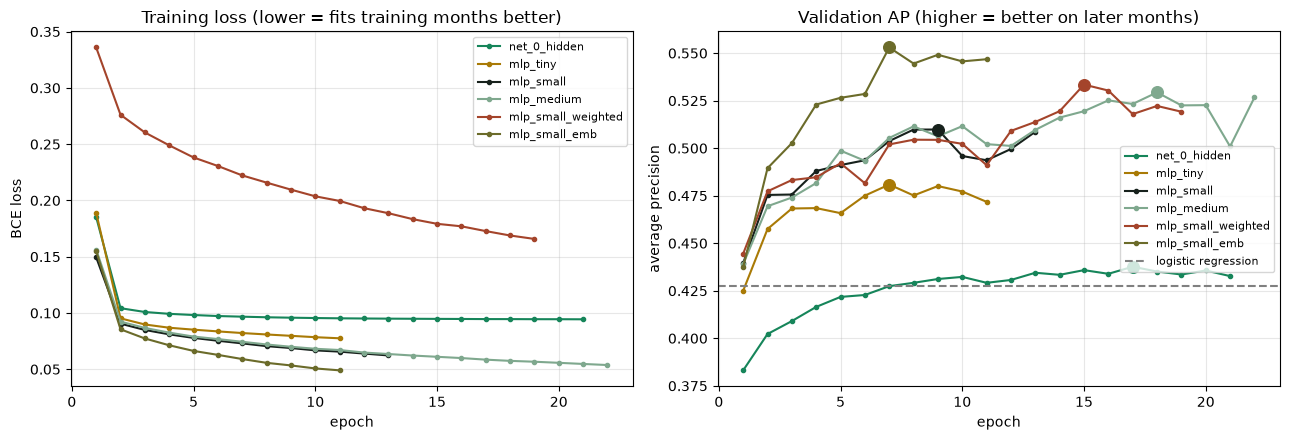

In [11]:
# [Eric] Section 10 — learning curves
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for (name, seed), h in HISTORIES.items():
    if seed != 0:
        continue
    axes[0].plot(h.epoch, h.train_loss, marker=".", label=name)
    line, = axes[1].plot(h.epoch, h.val_ap, marker=".", label=name)
    b = h.loc[h.val_ap.idxmax()]
    axes[1].scatter([b.epoch], [b.val_ap], s=70, color=line.get_color(), zorder=3)
axes[0].set(title="Training loss (lower = fits training months better)", xlabel="epoch", ylabel="BCE loss")
axes[1].set(title="Validation AP (higher = better on later months)", xlabel="epoch", ylabel="average precision")
axes[1].axhline(RESULTS[[r["model"] for r in RESULTS].index("logistic_regression")]["pr_auc"],
                ls="--", color="gray", label="logistic regression")
for ax in axes:
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT_DIR / "learning_curves.png", dpi=150); plt.show()

### 10a. What I see — learning curves
**[Eric]** Every network shows the same pattern:

- **Training loss falls every epoch** (for example `mlp_small_emb`: 0.155 → 0.049).
- **Validation AP rises fast in the first few epochs, then flattens or slips** (`mlp_small_emb`: 0.437 after epoch 1, peak 0.553 at epoch 7, 0.547 at the end; `mlp_small_weighted`: peak 0.533, then 0.519).
- That gap — training keeps improving while validation stops — is the start of **over-fitting**: the network is learning patterns specific to the training months. Early stopping keeps the peak epoch, so the scores in this notebook are from the best point, not the last one.
- The bigger network (`mlp_medium`) and the zero-hidden-layer model needed the most epochs (18 and 17) before peaking; the embedding model needed the fewest.

## 11. Is the best network stable? Three random seeds (Q5)

**Why:** a network starts from random weights and sees the mini-batches in a random order. Two runs with different seeds can differ by chance. If the gap between two models is smaller than the seed-to-seed spread, we should not claim one is better.

**What I'm doing:** retraining the best network from Experiments 1–3 with seeds 0, 1 and 2 (seed 0 is reused from above), plus the plain `mlp_small` for comparison, and reporting mean ± standard deviation.

In [12]:
# [Eric] Section 11 — seed stability
nets = pd.DataFrame(RESULTS)
nets = nets[nets.model.str.startswith("mlp") & (nets.seed == 0)]
BEST_NET = nets.sort_values("pr_auc", ascending=False).iloc[0]["model"]
CONFIGS = {"net_0_hidden": dict(hidden=(), dropout=0.0),
           "mlp_tiny": dict(hidden=(64,), dropout=0.1),
           "mlp_small": dict(hidden=(256, 128), dropout=0.2),
           "mlp_medium": dict(hidden=(512, 256, 128), dropout=0.3),
           "mlp_small_weighted": dict(hidden=(256, 128), dropout=0.2, pos_weight=POS_WEIGHT),
           "mlp_small_emb": dict(hidden=(256, 128), dropout=0.2, use_embeddings=True)}
print("Best network on seed 0:", BEST_NET)
for name in dict.fromkeys([BEST_NET, "mlp_small"]):
    for seed in SEEDS_FOR_STABILITY:
        if (name, seed) not in SCORES:
            run_experiment(name, "Q5 stability", seed=seed, **CONFIGS[name])

stab = pd.DataFrame(RESULTS)
stab = stab[stab.model.isin([BEST_NET, "mlp_small"])].groupby("model")[["pr_auc", "roc_auc", "recall_at_1pct_fpr"]]
stability = stab.agg(["mean", "std", "min", "max"]).round(4)
display(stability)
stability.to_csv(OUT_DIR / "seed_stability.csv")

Best network on seed 0: mlp_small_emb
mlp_small_emb (seed 1): loaded saved predictions
   -> val AP 0.5721 | ROC-AUC 0.9066 | recall@1%FPR 0.515 | best epoch 16 | 266,055 weights
mlp_small_emb (seed 2): loaded saved predictions
   -> val AP 0.5542 | ROC-AUC 0.9004 | recall@1%FPR 0.501 | best epoch 14 | 266,055 weights
mlp_small (seed 1): loaded saved predictions
   -> val AP 0.5157 | ROC-AUC 0.8874 | recall@1%FPR 0.453 | best epoch 10 | 165,889 weights
mlp_small (seed 2): loaded saved predictions
   -> val AP 0.5187 | ROC-AUC 0.8965 | recall@1%FPR 0.459 | best epoch 15 | 165,889 weights


pr_auc                         roc_auc                          \
                 mean     std     min     max    mean     std     min     max   
model                                                                           
mlp_small      0.5147  0.0045  0.5098  0.5187  0.8920  0.0046  0.8874  0.8965   
mlp_small_emb  0.5598  0.0107  0.5530  0.5721  0.9035  0.0031  0.9004  0.9066   

              recall_at_1pct_fpr                          
                            mean     std     min     max  
model                                                     
mlp_small                 0.4527  0.0065  0.4462  0.4592  
mlp_small_emb             0.5048  0.0088  0.4986  0.5149

### 11a. What I see — seed stability
**[Eric]** Three seeds each (validation AP):

| Model | Seed 0 | Seed 1 | Seed 2 | Mean ± std |
|---|---:|---:|---:|---:|
| `mlp_small` | 0.510 | 0.516 | 0.519 | **0.515 ± 0.005** |
| `mlp_small_emb` | 0.553 | 0.572 | 0.554 | **0.560 ± 0.011** |

- The **worst** embedding run (0.553) beats the **best** plain run (0.519). The +0.045 gain from embeddings is about 4–10× the seed-to-seed spread, so I'm confident it is real on this validation period.
- The embedding model wobbles more between seeds (±0.011 vs ±0.005). Rare categories get only a few updates, so their learned vectors depend more on the random start.
- Recall at 1% FPR: 45.3% (plain) vs 50.5% (embeddings), 3-seed means.

## 12. Tree reference: LightGBM retrained here (team Track A settings)

**Why retrain it instead of copying the team's number?** Two reasons. (1) I need LightGBM's validation **scores row by row** for the blend (Section 14) and the error comparison (Section 17). (2) Training it on the same machine and the same files makes the comparison clean.

**Settings:** identical to the team's Track A: feature set `all` on the tree table, learning rate 0.05, 63 leaves, early stopping after 100 rounds without AP improvement, seed 0. The team got AP 0.6315 with seed 0; mine should be close (small differences can come from library versions and thread counts).

In [13]:
# [Eric] Section 12 — LightGBM reference (team Track A parameters, seed 0), trained in a separate Python process
# Why a separate process? On macOS, PyTorch and LightGBM each bring their own OpenMP threading library.
# Loaded together in one process they can deadlock (LightGBM freezes at 0% CPU). A fresh process avoids that.
import subprocess, sys, textwrap

lgb_file = OUT_DIR / "lightgbm_all__seed0_val_predictions.parquet"
lgb_info_file = OUT_DIR / "lightgbm_all__seed0.json"
if not (lgb_file.exists() and lgb_info_file.exists()) or RETRAIN:
    lgb_script = textwrap.dedent(f'''
        import json, time
        from pathlib import Path
        import pandas as pd, lightgbm as lgb
        fe, out = Path({str(FE_DIR.resolve())!r}), Path({str(OUT_DIR.resolve())!r})
        cols = json.loads((fe / "manifest.json").read_text())["feature_sets"]["all"]
        Xtr, Xva = pd.read_parquet(fe / "X_tree_train.parquet")[cols], pd.read_parquet(fe / "X_tree_validation.parquet")[cols]
        ytr = pd.read_parquet(fe / "y_train.parquet")["isFraud"]; yva = pd.read_parquet(fe / "y_validation.parquet")["isFraud"]
        t0 = time.perf_counter()
        m = lgb.LGBMClassifier(objective="binary", metric="average_precision", n_estimators=6000, learning_rate=0.05,
                               num_leaves=63, min_child_samples=100, subsample=0.8, subsample_freq=1,
                               colsample_bytree=0.5, reg_lambda=1.0, random_state=0, n_jobs={N_THREADS}, verbosity=-1)
        m.fit(Xtr, ytr, eval_set=[(Xva, yva)], callbacks=[lgb.early_stopping(100, first_metric_only=True, verbose=False)])
        pd.DataFrame({{"row_index": Xva.index, "y": yva.to_numpy(), "score": m.predict_proba(Xva)[:, 1]}}).to_parquet(out / "{lgb_file.name}")
        (out / "{lgb_info_file.name}").write_text(json.dumps({{"best_iteration": int(m.best_iteration_),
                                                               "seconds": time.perf_counter() - t0, "lightgbm": lgb.__version__}}))
    ''')
    print("Training LightGBM in a fresh process (a few minutes)...")
    subprocess.run([sys.executable, "-c", lgb_script], check=True)
else:
    print("LightGBM: loaded saved predictions")

lgb_pred = pd.read_parquet(lgb_file)
assert np.array_equal(lgb_pred.row_index.to_numpy(), Xn_val.index.to_numpy()), "LightGBM rows do not line up"
lgb_score, lgb_info = lgb_pred["score"].to_numpy(), json.loads(lgb_info_file.read_text())

RESULTS.append({"model": "lightgbm_all", "question": "tree reference", "seed": 0, "n_params": np.nan,
                "best_epoch": lgb_info["best_iteration"], "train_minutes": lgb_info["seconds"] / 60,
                **evaluate(y_val, lgb_score, amount_val)})
SCORES[("lightgbm_all", 0)] = lgb_score
print(f"best iteration {lgb_info['best_iteration']} | {lgb_info['seconds']/60:.1f} min")
display(show(["lightgbm_all"]))

LightGBM: loaded saved predictions
best iteration 1351 | 2.6 min


,model,seed,n_params,best_epoch,pr_auc,roc_auc,ks,recall_at_1pct_fpr,tfpr_at_50pct_detection,tfpr_at_80pct_detection,fraud_cases_top5pct,fraud_dollars_top5pct
11,lightgbm_all,0,NaN,1351.0,0.6315,0.9308,0.7282,0.564,0.3434,2.9838,0.684,0.6402


## 13. Scoreboard: every model on the same validation transactions

**What I'm doing:** one table with every model (seed 0), plus precision–recall and ROC curves. For the team's other models I add the numbers already reported in the baseline notebook (XGBoost) so everything is in one place.

**How to read the table:** start with `pr_auc` (higher is better; random ≈ 0.031). Then `recall_at_1pct_fpr` — out of 100 frauds, how many we catch if we may flag at most 1% of legitimate customers. Then `tfpr_at_50pct_detection` — legitimate alerts per fraud caught when we catch half the fraud (lower is better).

,n_params,best_epoch,train_minutes,pr_auc,roc_auc,ks,recall_at_1pct_fpr,tfpr_at_50pct_detection,tfpr_at_80pct_detection,fraud_cases_top5pct,fraud_dollars_top5pct
model,,,,,,,,,,,
logistic_regression,516.0,NaN,NaN,0.4273,0.8668,0.5699,0.3760,1.9935,9.0804,0.5084,0.4658
net_0_hidden,516.0,17.0,0.4194,0.4377,0.8534,0.5546,0.3803,2.0151,10.7718,0.5073,0.4671
mlp_tiny,33217.0,7.0,0.2674,0.4809,0.8820,0.6164,0.4111,1.5670,7.8697,0.5451,0.5072
mlp_small,165889.0,9.0,0.5741,0.5098,0.8921,0.6327,0.4462,1.1004,6.6523,0.5775,0.5539
mlp_medium,430337.0,18.0,1.9022,0.5294,0.8882,0.6334,0.4787,0.7927,6.9669,0.6013,0.5724
mlp_small_weighted,165889.0,15.0,0.8649,0.5335,0.8968,0.6502,0.4641,0.8510,5.8994,0.5889,0.5527
mlp_small_emb,266055.0,7.0,0.6034,0.5530,0.9034,0.6529,0.4986,0.6285,5.8798,0.6056,0.5365
lightgbm_all,NaN,1351.0,2.5724,0.6315,0.9308,0.7282,0.5640,0.3434,2.9838,0.6840,0.6402


For reference, numbers the team already reported:


,model,pr_auc,source
0,"xgboost (team, int-coded, 3-seed mean)",0.6130,baseline notebook §6d3/§13
1,"lightgbm_all (team, seed 0)",0.6315,baseline notebook §8a
2,logistic_regression (team),0.4276,baseline notebook §8a


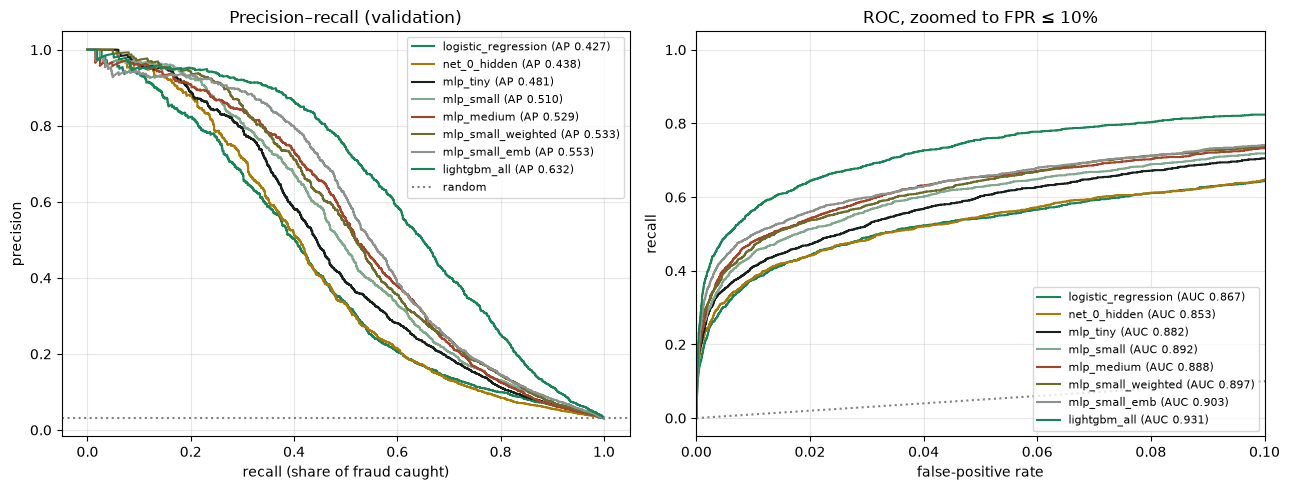

In [14]:
# [Eric] Section 13 — scoreboard and curves
board = pd.DataFrame(RESULTS).query("seed == 0").drop_duplicates("model")
order = ["logistic_regression", "net_0_hidden", "mlp_tiny", "mlp_small", "mlp_medium", "mlp_small_weighted", "mlp_small_emb", "lightgbm_all"]
board = board.set_index("model").loc[[m for m in order if m in set(board.model)]]
cols = ["n_params", "best_epoch", "train_minutes"] + HEADLINE
display(board[cols].round(4))
board.to_csv(OUT_DIR / "scoreboard_seed0.csv")

team_reported = pd.DataFrame([
    {"model": "xgboost (team, int-coded, 3-seed mean)", "pr_auc": 0.613, "source": "baseline notebook §6d3/§13"},
    {"model": "lightgbm_all (team, seed 0)", "pr_auc": 0.6315, "source": "baseline notebook §8a"},
    {"model": "logistic_regression (team)", "pr_auc": 0.4276, "source": "baseline notebook §8a"}])
print("For reference, numbers the team already reported:")
display(team_reported)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name in board.index:
    s = SCORES[(name, 0)]
    p, r, _ = precision_recall_curve(y_val, s)
    axes[0].plot(r, p, label=f"{name} (AP {board.loc[name, 'pr_auc']:.3f})")
    f, t, _ = roc_curve(y_val, s)
    axes[1].plot(f, t, label=f"{name} (AUC {board.loc[name, 'roc_auc']:.3f})")
axes[0].axhline(y_val.mean(), ls=":", color="gray", label="random")
axes[0].set(title="Precision–recall (validation)", xlabel="recall (share of fraud caught)", ylabel="precision")
axes[1].plot([0, 1], [0, 1], ls=":", color="gray")
axes[1].set(title="ROC, zoomed to FPR ≤ 10%", xlabel="false-positive rate", ylabel="recall", xlim=(0, 0.1))
for ax in axes:
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT_DIR / "pr_roc_curves.png", dpi=150); plt.show()

### 13a. Operating points: what would an analyst team actually experience?

**What I'm doing:** for the advisor's detection targets (catch 50%, 70%, 80%, 90% of fraud), how many legitimate payments get flagged per fraud caught (TFPR), and what share of all transactions must be reviewed. This turns AP into workload.

In [15]:
# [Eric] Section 13a — TFPR and review rate at detection targets
rows = []
for name in board.index:
    r = board.loc[name]
    for t in [50, 70, 80, 90]:
        rows.append({"model": name, "detection_target": f"{t}%", "TFPR (legit alerts per fraud)": r[f"tfpr_at_{t}pct_detection"],
                     "share of transactions reviewed": r[f"review_rate_at_{t}pct_detection"]})
op_table = pd.DataFrame(rows).pivot(index="model", columns="detection_target")
display(op_table.loc[board.index].round(3))
op_table.to_csv(OUT_DIR / "operating_points.csv")

TFPR (legit alerts per fraud)                         \
detection_target                              50%    70%     80%     90%   
model                                                                      
logistic_regression                         1.994  6.194   9.080  14.338   
net_0_hidden                                2.015  6.632  10.772  16.866   
mlp_tiny                                    1.567  4.241   7.870  13.833   
mlp_small                                   1.100  3.872   6.652  12.649   
mlp_medium                                  0.793  3.400   6.967  14.156   
mlp_small_weighted                          0.851  3.158   5.899  12.442   
mlp_small_emb                               0.629  3.150   5.880  11.335   
lightgbm_all                                0.343  1.478   2.984   7.811   

                    share of transactions reviewed                       
detection_target                               50%    70%    80%    90%  
model                                                                    
logistic_regression                          0.047  0.158  0.253  0.433  
net_0_hidden                                 0.047  0.167  0.295  0.504  
mlp_tiny                                     0.040  0.115  0.222  0.418  
mlp_small                                    0.033  0.107  0.192  0.385  
mlp_medium                                   0.028  0.097  0.200  0.428  
mlp_small_weighted                           0.029  0.091  0.173  0.379  
mlp_small_emb                                0.026  0.091  0.173  0.348  
lightgbm_all                                 0.021  0.054  0.100  0.249

### 13b. What I see — scoreboard
**[Eric]** Putting everything side by side (seed 0):

- **My LightGBM reproduces the team's number exactly (AP 0.6315)**, and my logistic regression matches too (0.4273 vs 0.4276). So my data loading is the same as the team's, and the comparison is fair.
- **Neural nets sit between logistic regression and the trees on every metric.** Best net (`mlp_small_emb`) AP 0.553 vs LightGBM 0.632: a gap of about **0.07–0.08 AP** (0.072 against the 3-seed mean).
- **Workload view (Section 13a):** to catch 50% of fraud, LightGBM flags 0.34 legitimate payments per fraud caught, the best net 0.63, logistic regression 1.99. To catch 90%, LightGBM needs 7.8, the best net 11.3, logistic regression 14.3. **Only LightGBM stays under a 10:1 ratio at 90% detection.**
- Training cost is not the problem: the best net trains in about 0.6 minutes vs 2.6 minutes for LightGBM on the same CPU.
- **Why are trees still ahead?** Tree models handle missing values, extreme values and sharp cut-offs ("amount below $X") natively. The net only sees the standardized, median-filled table, where some of that information is smoothed away. This matches what most tabular-data benchmarks report.

## 14. Does the network add anything on top of LightGBM? (Q6)

**What I'm doing:** a **rank-average blend**. Each model's scores are converted to ranks between 0 and 1 (so the two score scales don't matter), then combined as `w × rank(net) + (1 − w) × rank(LightGBM)` for w = 0.1, 0.2, 0.3, 0.5.

**Is a gain real?** I use the same **time-block bootstrap** as the team (Section 6m of the baseline notebook): split validation into 100 consecutive time blocks, resample blocks with replacement 300 times, recompute `AP(blend) − AP(LightGBM)` each time. If the 95% interval stays above 0, the gain is unlikely to be luck *on this validation period*.

**Important:** choosing the weight on validation and judging it on validation is optimistic. If a blend looks useful, the weight must be fixed before the holdout test.

In [16]:
# [Eric] Section 14 — rank blend + time-block bootstrap
from scipy.stats import rankdata

meta_val = pd.read_parquet(FE_DIR / "metadata_validation.parquet").reindex(Xn_val.index)
time_order = np.argsort(meta_val["TransactionDT"].to_numpy(), kind="stable")
y_arr = y_val.to_numpy()

def block_bootstrap_delta(y, s_a, s_b, order, n_blocks=100, n_boot=300, seed=0):
    rng = np.random.default_rng(seed); blocks = np.array_split(order, n_blocks); deltas = []
    for _ in range(n_boot):
        idx = np.concatenate([blocks[i] for i in rng.integers(0, n_blocks, n_blocks)])
        deltas.append(average_precision_score(y[idx], s_a[idx]) - average_precision_score(y[idx], s_b[idx]))
    return {"delta_AP": average_precision_score(y, s_a) - average_precision_score(y, s_b),
            "ci_low": np.percentile(deltas, 2.5), "ci_high": np.percentile(deltas, 97.5)}

rank = lambda s: rankdata(s) / len(s)
net_score = SCORES[(BEST_NET, 0)]
blend_rows, BLENDS = [], {}
for w in [0.1, 0.2, 0.3, 0.5]:
    s = w * rank(net_score) + (1 - w) * rank(lgb_score)
    BLENDS[w] = s
    m = evaluate(y_val, s, amount_val)
    blend_rows.append({"blend": f"{w:.0%} {BEST_NET} + {1-w:.0%} LightGBM", **{k: m[k] for k in HEADLINE[:5]},
                       **block_bootstrap_delta(y_arr, s, lgb_score, time_order)})
blend_df = pd.DataFrame(blend_rows).set_index("blend")
display(blend_df.round(4))
blend_df.to_csv(OUT_DIR / "blend_results.csv")
print("delta_AP = AP(blend) - AP(LightGBM alone); interval excluding 0 means a gain unlikely to be luck on this period.")

,pr_auc,roc_auc,ks,recall_at_1pct_fpr,tfpr_at_50pct_detection,delta_AP,ci_low,ci_high
blend,,,,,,,,
10% mlp_small_emb + 90% LightGBM,0.6280,0.9312,0.7281,0.5662,0.3413,-0.0035,-0.0068,-0.0001
20% mlp_small_emb + 80% LightGBM,0.6234,0.9308,0.7249,0.5575,0.3715,-0.0081,-0.0138,-0.0028
30% mlp_small_emb + 70% LightGBM,0.6186,0.9298,0.7224,0.5489,0.3693,-0.0129,-0.0204,-0.0063
50% mlp_small_emb + 50% LightGBM,0.6081,0.9259,0.7083,0.5440,0.3996,-0.0234,-0.0328,-0.0150


delta_AP = AP(blend) - AP(LightGBM alone); interval excluding 0 means a gain unlikely to be luck on this period.


### 14a. What I see — blend
**[Eric]** **No — blending makes LightGBM worse.**

- Every blend weight lowered AP, and the more weight the net gets, the worse it is: −0.0035 at 10%, −0.008 at 20%, −0.013 at 30%, −0.023 at 50%.
- Even the 10% blend's 95% interval (−0.0068 to −0.0001) stays below zero, so this is not just noise.
- So **Q6 is answered "no" for now**. This matches the team's earlier finding that blending logistic regression with the trees also hurt. Section 17 shows why: the network mostly finds the same frauds LightGBM already finds.

## 15. Are the network's scores real probabilities? Calibration (Q7)

**Why it matters:** if the model says "0.30", do about 30% of such transactions turn out to be fraud? A fraud team that sets thresholds by review budget only needs good *ranking*; anyone quoting "probability of fraud" needs *calibration*.

**What I'm doing:** grouping validation transactions into 15 bins by predicted score (equal number of transactions per bin) and plotting the average predicted score against the actual fraud rate. The diagonal is perfect calibration. I also report the **Brier score** (mean squared error of the probability; lower is better). Logistic regression used `class_weight="balanced"`, and `mlp_small_weighted` used `pos_weight`, so I expect both to sit **below** the diagonal (scores too high).

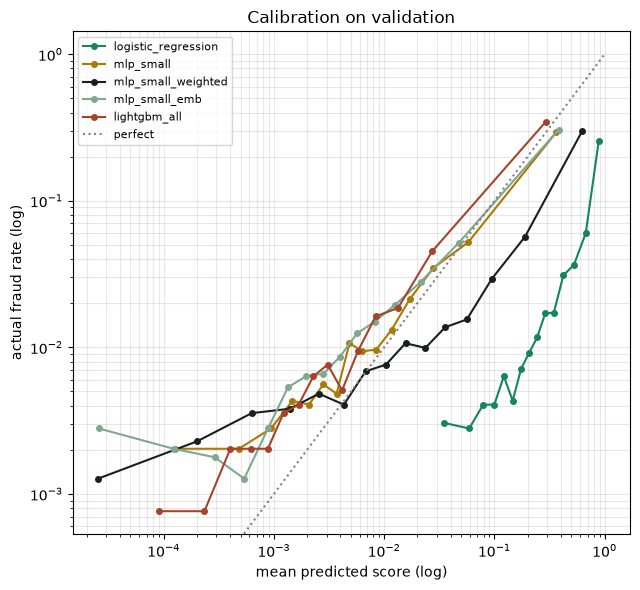

,brier,mean_score,actual_fraud_rate
logistic_regression,0.1264,0.2871,0.0313
mlp_small,0.0211,0.0340,0.0313
mlp_small_weighted,0.0299,0.0712,0.0313
mlp_small_emb,0.0197,0.0326,0.0313
lightgbm_all,0.0174,0.0241,0.0313


In [17]:
# [Eric] Section 15 — calibration
from sklearn.calibration import calibration_curve

cal_models = [m for m in ["logistic_regression", "mlp_small", "mlp_small_weighted", BEST_NET, "lightgbm_all"] if (m, 0) in SCORES]
cal_models = list(dict.fromkeys(cal_models))
fig, ax = plt.subplots(figsize=(6.5, 6))
brier = {}
for name in cal_models:
    s = SCORES[(name, 0)]
    frac_pos, mean_pred = calibration_curve(y_val, s, n_bins=15, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", ms=4, label=name)
    brier[name] = {"brier": brier_score_loss(y_val, s), "mean_score": s.mean(), "actual_fraud_rate": y_val.mean()}
ax.plot([0, 1], [0, 1], ls=":", color="gray", label="perfect")
ax.set(xscale="log", yscale="log", xlabel="mean predicted score (log)", ylabel="actual fraud rate (log)",
       title="Calibration on validation")
ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT_DIR / "calibration.png", dpi=150); plt.show()
display(pd.DataFrame(brier).T.round(4))

### 15a. What I see — calibration
**[Eric]** Ranking and probability are two different things:

| Model | Average score | Actual fraud rate | Brier (lower is better) |
|---|---:|---:|---:|
| Logistic regression (`class_weight="balanced"`) | 0.287 | 0.031 | 0.126 |
| `mlp_small_weighted` (`pos_weight` 5.2) | 0.071 | 0.031 | 0.030 |
| `mlp_small` (no weighting) | 0.034 | 0.031 | 0.021 |
| `mlp_small_emb` (no weighting) | 0.033 | 0.031 | 0.020 |
| LightGBM | 0.024 | 0.031 | 0.017 |

- The **unweighted networks are close to calibrated**: their average score (0.033) is almost exactly the true fraud rate (0.031), and their curve follows the diagonal.
- **Weighting inflates scores**: the weighted net over-states risk about 2×, and balanced logistic regression about 9×. Their *ranking* is still fine, but you can't read their score as "chance of fraud".
- If we ever show a score to an analyst as a probability, use an unweighted model (or recalibrate on validation first).

## 16. Where does the network do well or badly? Segment check (Q7)

**What I'm doing:** splitting validation transactions into groups the EDA flagged as important — product type (`ProductCD`), whether identity data exists, and whether the billing address (`addr1`) is missing — and computing AP for the best network and for LightGBM within each group.

**How to read it:** compare the two models **within a row**. Don't compare AP across rows: a group with more fraud has a higher AP even for a random model (the `fraud_rate` column shows each group's random baseline). Groups with fewer than 30 frauds are skipped because their AP is too noisy.

In [18]:
# [Eric] Section 16 — segment analysis
def is_missing(col):
    s = X_tree_val[col]
    return (s.isna() | s.astype("object").astype(str).isin(["__MISSING__", "nan", "<NA>"])).to_numpy()

segments = {f"ProductCD = {p}": (X_tree_val["ProductCD"].astype(str) == p).to_numpy()
            for p in sorted(X_tree_val["ProductCD"].astype(str).unique())}
segments["identity present"] = ~is_missing("DeviceType") | ~is_missing("id_12")
segments["identity missing"] = ~segments["identity present"]
segments["addr1 missing"] = is_missing("addr1")
segments["addr1 present"] = ~segments["addr1 missing"]

seg_rows = []
for seg, mask in segments.items():
    yy = y_arr[mask]
    if yy.sum() < 30 or (len(yy) - yy.sum()) < 30:
        continue
    row = {"segment": seg, "rows": int(mask.sum()), "frauds": int(yy.sum()), "fraud_rate": yy.mean()}
    for name in dict.fromkeys(["logistic_regression", BEST_NET, "lightgbm_all"]):
        row[f"AP {name}"] = average_precision_score(yy, SCORES[(name, 0)][mask])
    seg_rows.append(row)
seg_df = pd.DataFrame(seg_rows).set_index("segment")
seg_df["net minus LightGBM"] = seg_df[f"AP {BEST_NET}"] - seg_df["AP lightgbm_all"]
display(seg_df.round(4))
seg_df.to_csv(OUT_DIR / "segment_ap.csv")

,rows,frauds,fraud_rate,AP logistic_regression,AP mlp_small_emb,AP lightgbm_all,net minus LightGBM
segment,,,,,,,
ProductCD = C,5628,666,0.1183,0.7314,0.7557,0.8040,-0.0483
ProductCD = H,1561,85,0.0545,0.4640,0.5276,0.6249,-0.0973
ProductCD = R,2558,120,0.0469,0.7235,0.8137,0.8581,-0.0443
ProductCD = S,1064,70,0.0658,0.3237,0.5823,0.6679,-0.0856
ProductCD = W,48243,910,0.0189,0.1160,0.3562,0.4614,-0.1052
identity present,10360,925,0.0893,0.6835,0.7342,0.7874,-0.0532
identity missing,48694,926,0.0190,0.1176,0.3577,0.4615,-0.1038
addr1 missing,5486,664,0.1210,0.7377,0.7583,0.8061,-0.0477
addr1 present,53568,1187,0.0222,0.2192,0.4325,0.5291,-0.0967


### 16a. What I see — segments
**[Eric]** (Compare within a row, not across rows.)

- **The net is behind LightGBM in every segment**, but the size of the gap differs:
  - **Smallest gap (≈ −0.045 to −0.05 AP):** product C, product R, address missing, identity present — segments where fraud is concentrated and identity/device data exists.
  - **Largest gap (≈ −0.10 AP):** product W and identity missing. These are the big, low-fraud-rate segments (48,000+ rows each). The team already flagged product W as the weakest segment for XGBoost.
- **The net is far better than logistic regression where it matters most:** on product W, AP rises from 0.116 (logistic) to 0.356 (net), about 3×.
- Takeaway: if we want to improve the net, product W / no-identity transactions are where the remaining gap lives.

## 17. Do the network and LightGBM catch the *same* frauds?

**Why:** a blend can only help if the models make different mistakes. Here I pretend analysts review the top 5% of transactions for each model and count which frauds each one catches.

In [19]:
# [Eric] Section 17 — overlap of caught fraud at a 5% review budget
def caught_top(score, rate=0.05):
    thr = np.sort(score)[::-1][int(round(len(score) * rate)) - 1]
    return (score >= thr) & (y_arr == 1)

c_net, c_lgb = caught_top(net_score), caught_top(lgb_score)
n_fraud = int(y_arr.sum())
overlap = pd.Series({
    "fraud in validation": n_fraud,
    "caught by both": int((c_net & c_lgb).sum()),
    "caught only by LightGBM": int((~c_net & c_lgb).sum()),
    f"caught only by {BEST_NET}": int((c_net & ~c_lgb).sum()),
    "missed by both": int((~c_net & ~c_lgb & (y_arr == 1)).sum()),
})
display(overlap.to_frame("count").assign(share_of_fraud=lambda d: (d["count"] / n_fraud).round(3)))
corr = pd.Series(net_score).rank().corr(pd.Series(lgb_score).rank())
print(f"Rank correlation between {BEST_NET} and LightGBM scores: {corr:.3f}")

,count,share_of_fraud
fraud in validation,1851,1.000
caught by both,1061,0.573
caught only by LightGBM,205,0.111
caught only by mlp_small_emb,60,0.032
missed by both,525,0.284


Rank correlation between mlp_small_emb and LightGBM scores: 0.720


### 17a. What I see — overlap
**[Eric]** At a 5% review budget (1,851 frauds in validation):

| | Frauds | Share |
|---|---:|---:|
| Caught by both | 1,061 | 57.3% |
| Caught only by LightGBM | 205 | 11.1% |
| Caught only by the net | 60 | 3.2% |
| Missed by both | 525 | 28.4% |

- The net's catches are **mostly a subset of LightGBM's** (rank correlation 0.72). It adds only 60 unique frauds while missing 205 that LightGBM finds — that is why blending didn't help.
- **525 frauds (28%) are missed by both models.** That's not a model-choice problem; it points to information neither model has. Those cases are the best place for new features.

## 18. Findings and decision log

**[Eric]** Same format as the team's decision log: question → evidence → what we can say → next action. All numbers are validation-period, the holdout is untouched.

| # | Question | Evidence (validation) | What we can say | Next action |
|---|---|---|---|---|
| Q1 | Do hidden layers beat logistic regression on the same inputs? | 0-hidden net 0.438 ≈ logistic 0.427; one hidden layer 0.481; 256→128 0.515 ± 0.005 (3 seeds) | **Yes.** Clear, repeatable gain from non-linear combinations. | Keep `mlp_small` as the neural-net baseline. |
| Q2 | Does a bigger network help? | 64 → 0.481; 256-128 → 0.510; 512-256-128 → 0.529 (seed 0), 3× training time | Small gains that shrink with size. | Use the medium size only together with the other improvements. |
| Q3 | Does weighting fraud rows help? | 0.510 → 0.533 (seed 0); scores inflated 2× | **Promising, not confirmed** (one seed). Hurts calibration. | Repeat with 3 seeds. |
| Q4 | Do category embeddings help? | 0.515 ± 0.005 → **0.560 ± 0.011** (3 seeds), ranges don't overlap | **Yes — the largest gain.** | Keep; try embeddings for more columns (e.g. account keys). |
| Q5 | How close to LightGBM? | Best net 0.560 (mean) vs LightGBM 0.632; TFPR at 90% detection 11.3 vs 7.8 | About **0.07 AP behind**; behind in every segment. | LightGBM stays the main model. |
| Q6 | Does blending help? | Every blend lowers AP; 10% blend −0.0035, interval excludes 0 | **No.** The net mostly finds the same frauds. | Don't blend unless the net improves a lot. |
| Q7 | Calibration and segments | Unweighted net average score 0.033 vs 0.031 actual; biggest gap on product W / no identity | Net scores are trustworthy probabilities; weak spot is the same as the trees'. | Target product W / no-identity cases with features. |

### Suggested explanation for the team (and the advisor)

> We trained small neural networks on the same numeric table as logistic regression. With no hidden layers the network is just logistic regression (AP ≈ 0.43). Adding hidden layers raised AP to about 0.51–0.53, and giving the network learned *embeddings* for ID-like columns such as `card1`, `addr1`, email domain and device raised it to **0.56 (3-seed mean)** — a gain much bigger than random seed noise. The best network catches about 50 of 100 frauds at a 1% false-alarm budget, versus 38 for logistic regression and 56 for LightGBM. LightGBM is still about 0.07 AP ahead, it is ahead in every segment, and blending the network into LightGBM made things slightly worse because the network mostly finds frauds LightGBM already finds. **Our recommendation: keep LightGBM as the main model, keep the embedding network as the documented deep-learning baseline, and spend remaining time on the 28% of fraud that both models miss.**

### Limitations (please keep these in mind when quoting numbers)

- **Validation is used twice** — for early stopping and for picking the best model — so every number here is slightly optimistic. The holdout will give the honest estimate.
- Most comparisons are **one seed**; only `mlp_small` and `mlp_small_emb` have three. Differences under ~0.01 AP should be treated as noise.
- **No hyperparameter tuning** (learning rate, batch size, dropout, embedding size were sensible defaults). A tuned network might close some of the gap — but the trees aren't tuned either.
- One validation period (~3 weeks). Fraud patterns drift over time.

### Next steps (proposed)

1. Combine the two things that helped: **embeddings + fraud weighting** (and medium size), over 3 seeds.
2. Try embeddings for the team's account keys, so the net sees account identity directly.
3. Look at the 525 frauds both models miss (mostly product W / no identity?) and discuss new features with the team.
4. If time allows, a small sequence model (GRU) over each account's recent transactions — the one thing a neural net can do that trees cannot do easily.
5. Once the team freezes the final model, score the holdout **once**.

## 19. Save everything for the team

**What I'm doing:** writing the full results table (every model, every seed) and a small JSON record of settings and library versions to `outputs/feature_engineering/fe_final_v1/neural_nets/eric_v1/`. The `outputs/` folder is ignored by Git, so these files stay local; the tables above are saved inside this notebook.

In [20]:
# [Eric] Section 19 — save results and a reproducibility record
import platform, sklearn
all_results = pd.DataFrame(RESULTS)
all_results.to_csv(OUT_DIR / "all_results.csv", index=False)
record = {"author": "Kyaw Thi (Eric) Ha", "notebook": "BTT_Mastercard_Small_Neural_Nets_Eric.ipynb",
          "data": str(FE_DIR), "train_rows": len(Xn_train), "validation_rows": len(Xn_val), "holdout_used": False,
          "train_settings": TRAIN_SETTINGS, "configs": {k: {kk: str(vv) for kk, vv in v.items()} for k, v in CONFIGS.items()},
          "embedding_columns": emb_cols, "best_network": BEST_NET,
          "versions": {"python": platform.python_version(), "torch": torch.__version__, "sklearn": sklearn.__version__,
                       "lightgbm": lgb_info.get("lightgbm"), "pandas": pd.__version__, "numpy": np.__version__}}
(OUT_DIR / "record.json").write_text(json.dumps(record, indent=2))
print("Saved:", sorted(p.name for p in OUT_DIR.glob("*.csv")) + ["record.json"])

Saved: ['all_results.csv', 'blend_results.csv', 'operating_points.csv', 'scoreboard_seed0.csv', 'seed_stability.csv', 'segment_ap.csv', 'record.json']
